# РГР 1 по математической статистике - вариант A-2.
# Выполнил Григорьев Даниил Александрович, поток 21.1, P3216

**Группа:** A  
**Единицы измерения:** мс  
**Объём выборки:** $n = 200$  
**Столбцы:** `X1`, `X2`, `X3`, `X4`

Для `X1`, `X2`, `X3` нужно выполнить первичное описание выборки, выбрать модель распределения из набора $N(\mu,\sigma)$, $U(a,b)$, $\mathrm{Exp}(\lambda,c)$, оценить параметры методом моментов и методом максимального правдоподобия, сравнить эмпирические и параметрические вероятности, оценить моменты по сгруппированной выборке и построить доверительные интервалы. Для `X4` требуется первичное описание и вывод о возможной неоднородности данных.



## Подготовка
Ниже подключаются библиотеки и загружаются данные



In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from IPython.display import display, Markdown

plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
np.set_printoptions(suppress=True, precision=3)


In [2]:

candidate_paths = [
    Path("RGR1_A-2_X1-X4.csv"),
    Path("/mnt/data/RGR1_A-2_X1-X4.csv"),
    Path("RGR1_A-2_X1-X4.xlsx"),
    Path("/mnt/data/RGR1_A-2_X1-X4.xlsx"),
]

data_path = None
for p in candidate_paths:
    if p.exists():
        data_path = p
        break

if data_path is None:
    # Поиск по шаблону
    search_roots = [Path("."), Path("/mnt/data")]
    found = []
    for root in search_roots:
        found.extend(root.glob("*A-2*.csv"))
        found.extend(root.glob("*A-2*.xlsx"))
    if found:
        data_path = found[0]

if data_path is None:
    raise FileNotFoundError("Не удалось найти файл данных для варианта A-2.")

if data_path.suffix.lower() == ".csv":
    df = pd.read_csv(data_path)
else:
    df = pd.read_excel(data_path)

df.columns = [c.strip() for c in df.columns]
assert list(df.columns) == ["X1", "X2", "X3", "X4"], "Ожидались столбцы X1, X2, X3, X4"

n = len(df)
display(Markdown(f"**Файл данных:** `{data_path}`"))
display(df.head())
display(Markdown(f"**Размер таблицы:** {df.shape[0]} строк × {df.shape[1]} столбца"))


**Файл данных:** `RGR1_A-2_X1-X4.csv`

,X1,X2,X3,X4
0,47.73,33.93,50.92,118.81
1,39.01,31.50,204.28,107.52
2,44.94,65.94,67.03,38.81
3,52.82,32.80,34.55,33.95
4,53.82,63.95,25.68,100.77


**Размер таблицы:** 200 строк × 4 столбца

In [3]:

def sample_characteristics(x):
    x = np.asarray(x, dtype=float)
    q1, med, q3 = np.quantile(x, [0.25, 0.5, 0.75])
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    outliers = x[(x < lower_fence) | (x > upper_fence)]
    return {
        "n": len(x),
        "min": x.min(),
        "max": x.max(),
        "mean": x.mean(),
        "var_biased": x.var(ddof=0),
        "std_biased": x.std(ddof=0),
        "var_unbiased": x.var(ddof=1),
        "std_unbiased": x.std(ddof=1),
        "median": np.median(x),
        "q25": q1,
        "q75": q3,
        "iqr": iqr,
        "skewness": stats.skew(x, bias=False),
        "excess_kurtosis": stats.kurtosis(x, fisher=True, bias=False),
        "outliers_count": len(outliers),
    }

def sturges_bins(x):
    x = np.asarray(x)
    return int(np.ceil(1 + np.log2(len(x))))

def scott_bins(x):
    x = np.asarray(x)
    h = 3.5 * x.std(ddof=1) * len(x) ** (-1/3)
    if h <= 0:
        return sturges_bins(x)
    k = int(np.ceil((x.max() - x.min()) / h))
    return max(k, 1)

def fd_bins(x):
    x = np.asarray(x)
    q1, q3 = np.quantile(x, [0.25, 0.75])
    iqr = q3 - q1
    h = 2 * iqr * len(x) ** (-1/3)
    if h <= 0:
        return sturges_bins(x)
    k = int(np.ceil((x.max() - x.min()) / h))
    return max(k, 1)

def ecdf(x):
    x = np.sort(np.asarray(x))
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

def normal_cdf(x, mu, sigma):
    return stats.norm.cdf(x, loc=mu, scale=sigma)

def uniform_cdf(x, a, b):
    x = np.asarray(x, dtype=float)
    return np.clip((x - a) / (b - a), 0, 1)

def exp_shift_cdf(x, lam, c):
    x = np.asarray(x, dtype=float)
    y = np.zeros_like(x)
    mask = x >= c
    y[mask] = 1 - np.exp(-lam * (x[mask] - c))
    return y

def fit_models(x):
    x = np.asarray(x, dtype=float)
    mean = x.mean()
    S2 = x.var(ddof=0)
    S = x.std(ddof=0)
    minx = x.min()
    maxx = x.max()

    return {
        "normal": {
            "mom": {"mu": mean, "sigma": S},
            "mle": {"mu": mean, "sigma": S},
        },
        "uniform": {
            "mom": {"a": mean - np.sqrt(3 * S2), "b": mean + np.sqrt(3 * S2)},
            "mle": {"a": minx, "b": maxx},
        },
        "exp_shift": {
            "mom": {"lambda": 1 / S, "c": mean - S},
            "mle": {"lambda": 1 / (mean - minx), "c": minx},
        },
    }

def ks_like_score(x, model_name, params):
    x_sorted, Fn = ecdf(x)
    if model_name == "normal":
        F = normal_cdf(x_sorted, params["mu"], params["sigma"])
    elif model_name == "uniform":
        F = uniform_cdf(x_sorted, params["a"], params["b"])
    elif model_name == "exp_shift":
        F = exp_shift_cdf(x_sorted, params["lambda"], params["c"])
    else:
        raise ValueError("Неизвестная модель")
    return np.max(np.abs(Fn - F))

def grouped_moments(x, bins):
    counts, edges = np.histogram(x, bins=bins)
    mids = (edges[:-1] + edges[1:]) / 2
    mean_g = np.sum(counts * mids) / len(x)
    var_g = np.sum(counts * (mids - mean_g) ** 2) / (len(x) - 1)
    return mean_g, var_g, counts, edges, mids

def probability_greater_than(x0, model_name, params):
    if model_name == "normal":
        return 1 - stats.norm.cdf(x0, loc=params["mu"], scale=params["sigma"])
    if model_name == "uniform":
        a, b = params["a"], params["b"]
        if x0 <= a:
            return 1.0
        if x0 >= b:
            return 0.0
        return (b - x0) / (b - a)
    if model_name == "exp_shift":
        lam, c = params["lambda"], params["c"]
        if x0 <= c:
            return 1.0
        return np.exp(-lam * (x0 - c))
    raise ValueError("Неизвестная модель")



## 1. Первичное описание выборки
Для каждого столбца строятся:
- вариационный ряд;
- эмпирическая функция распределения $F_n(x)$;
- гистограммы по нескольким правилам выбора числа интервалов;
- числовые характеристики;
- краткое описание формы распределения.


In [4]:

variation_rows = {col: np.sort(df[col].to_numpy()) for col in df.columns}

for col in df.columns:
    x = variation_rows[col]
    preview = pd.DataFrame({
        "Первые 15 значений": x[:15],
        "Последние 15 значений": x[-15:]
    })
    display(Markdown(f"### {col}: вариационный ряд"))
    display(Markdown("Показаны начало и конец отсортированной выборки; полный вариационный ряд сохранён в переменной `variation_rows`."))
    display(preview)


### X1: вариационный ряд

Показаны начало и конец отсортированной выборки; полный вариационный ряд сохранён в переменной `variation_rows`.

,Первые 15 значений,Последние 15 значений
0,28.81,64.85
1,30.54,65.31
2,31.03,65.79
3,31.11,66.99
4,32.17,67.09
5,32.44,67.83
6,34.06,68.14
7,34.53,68.79
8,34.88,69.24
9,34.92,70.73


### X2: вариационный ряд

Показаны начало и конец отсортированной выборки; полный вариационный ряд сохранён в переменной `variation_rows`.

,Первые 15 значений,Последние 15 значений
0,26.80,69.59
1,27.00,69.96
2,27.53,70.14
3,27.57,70.23
4,27.62,70.77
5,28.39,71.11
6,28.61,71.15
7,28.71,71.17
8,29.35,71.43
9,29.58,71.81


... (2 outputs left out)

,Первые 15 значений,Последние 15 значений
0,22.47,169.96
1,22.76,184.21
2,22.89,184.57
3,22.98,197.89
4,23.53,204.28
5,23.80,210.72
6,24.05,212.02
7,24.47,217.20
8,25.21,234.82
9,25.68,236.95


### X4: вариационный ряд

Показаны начало и конец отсортированной выборки; полный вариационный ряд сохранён в переменной `variation_rows`.

,Первые 15 значений,Последние 15 значений
0,22.80,118.47
1,23.17,118.63
2,26.70,118.81
3,27.25,119.28
4,27.72,119.49
5,28.18,119.78
6,29.40,120.43
7,29.67,121.70
8,30.05,121.83
9,30.15,121.98


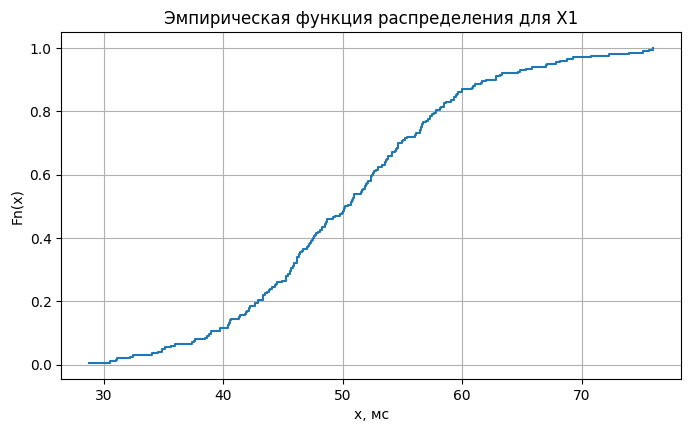

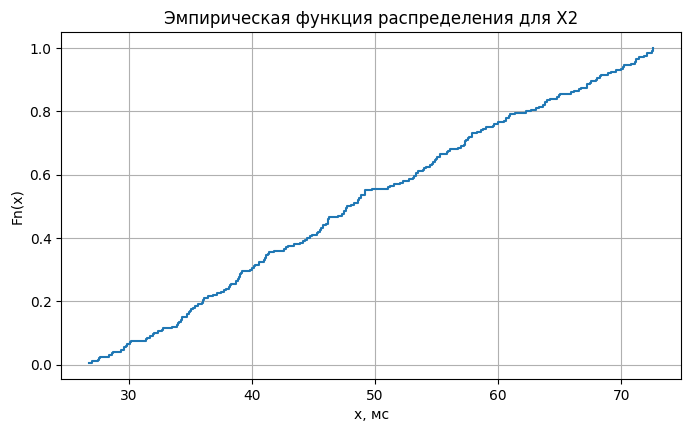

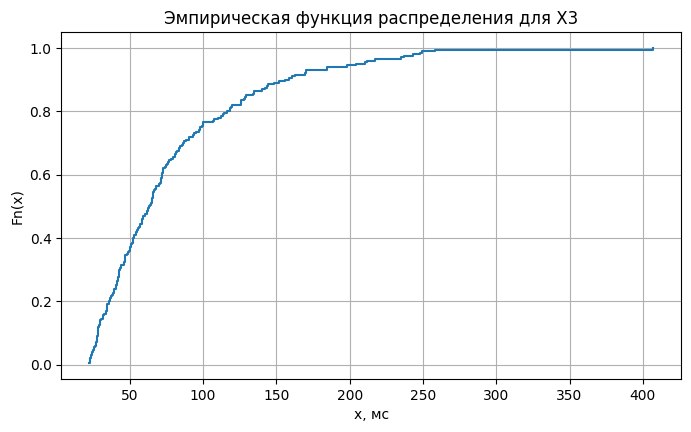

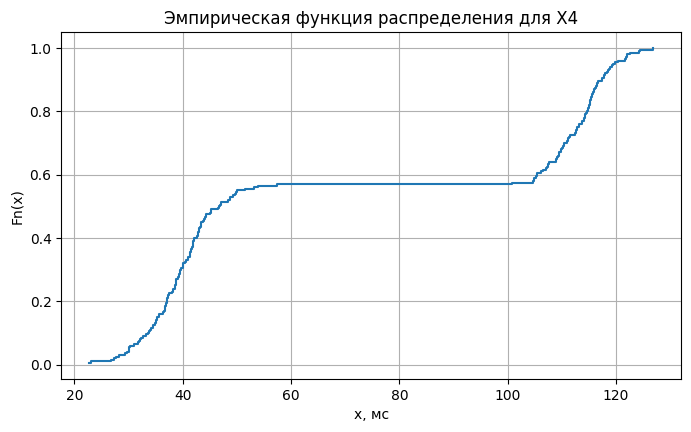

In [5]:

for col in df.columns:
    x = df[col].to_numpy()
    xs, ys = ecdf(x)
    plt.figure()
    plt.step(xs, ys, where="post")
    plt.title(f"Эмпирическая функция распределения для {col}")
    plt.xlabel("x, мс")
    plt.ylabel("Fn(x)")
    plt.show()


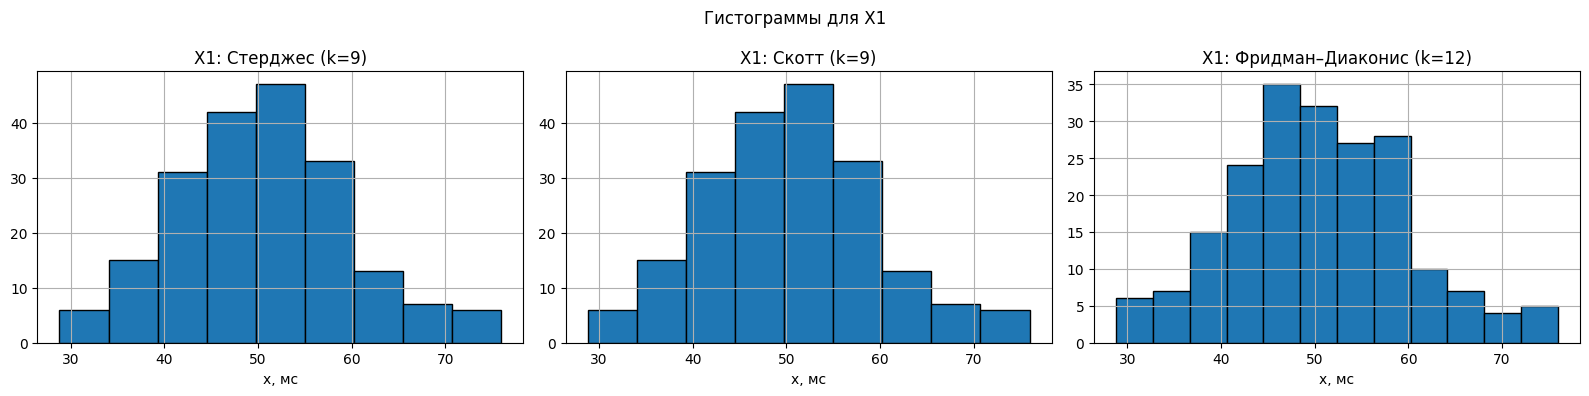

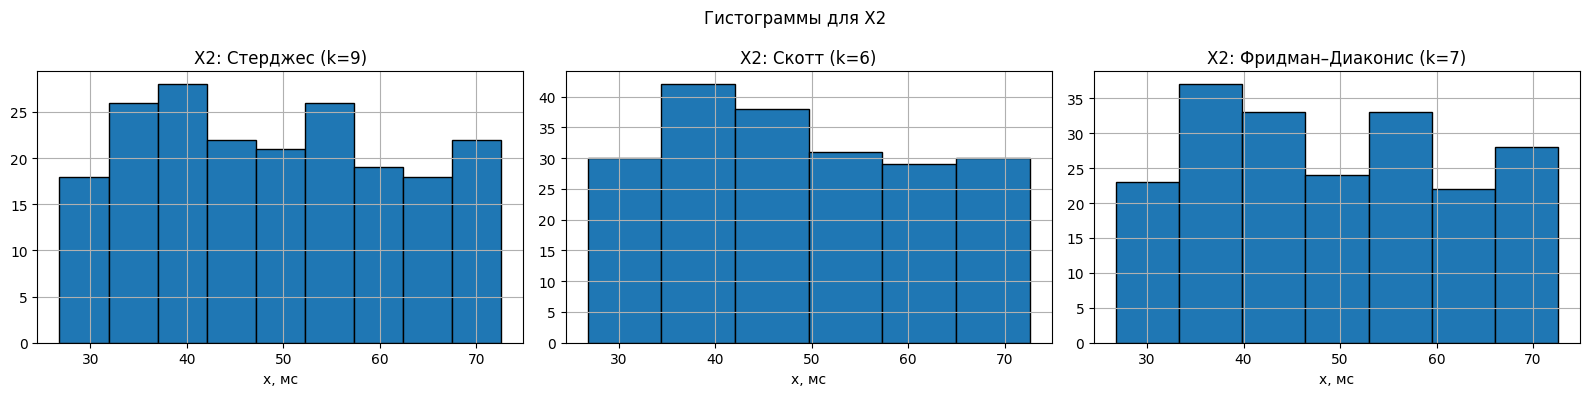

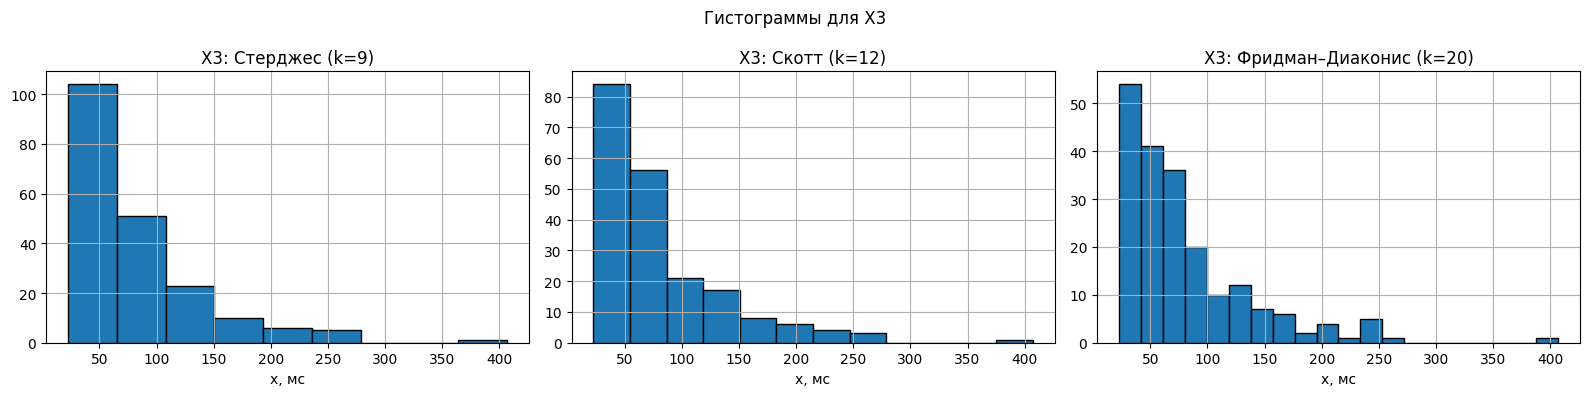

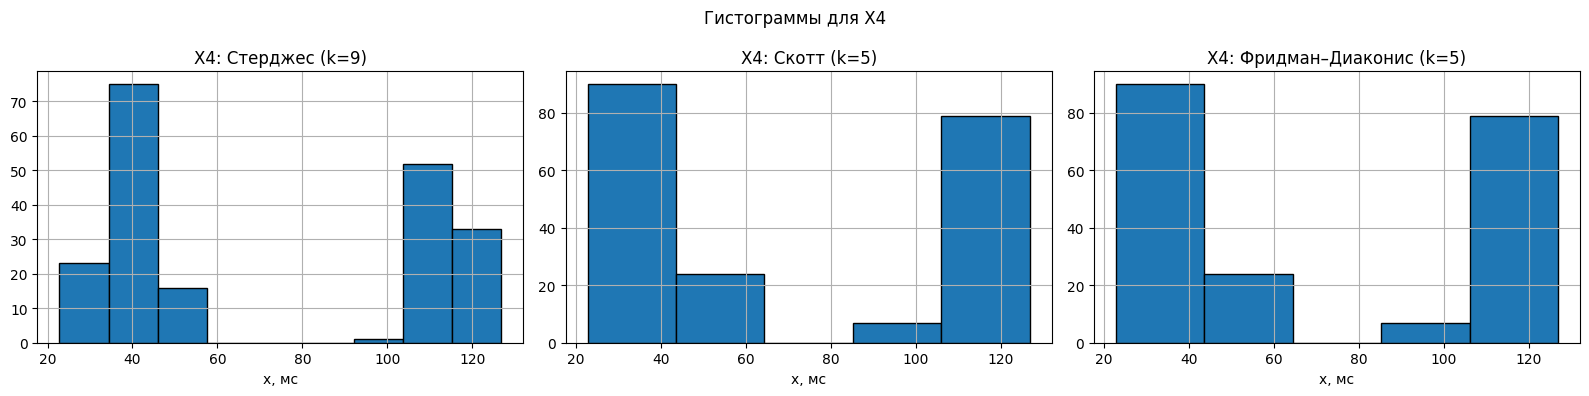

In [6]:

for col in df.columns:
    x = df[col].to_numpy()
    k_st = sturges_bins(x)
    k_sc = scott_bins(x)
    k_fd = fd_bins(x)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].hist(x, bins=k_st, edgecolor="black")
    axes[0].set_title(f"{col}: Стерджес (k={k_st})")
    axes[0].set_xlabel("x, мс")

    axes[1].hist(x, bins=k_sc, edgecolor="black")
    axes[1].set_title(f"{col}: Скотт (k={k_sc})")
    axes[1].set_xlabel("x, мс")

    axes[2].hist(x, bins=k_fd, edgecolor="black")
    axes[2].set_title(f"{col}: Фридман–Диаконис (k={k_fd})")
    axes[2].set_xlabel("x, мс")

    fig.suptitle(f"Гистограммы для {col}")
    plt.tight_layout()
    plt.show()


In [7]:

summary_df = pd.DataFrame({
    col: sample_characteristics(df[col].to_numpy()) for col in df.columns
}).T

summary_df_rounded = summary_df.copy()
for c in summary_df_rounded.columns:
    summary_df_rounded[c] = summary_df_rounded[c].astype(float).round(4)

display(Markdown("### Числовые характеристики"))
display(summary_df_rounded)


### Числовые характеристики

,n,min,max,mean,var_biased,std_biased,var_unbiased,std_unbiased,median,q25,q75,iqr,skewness,excess_kurtosis,outliers_count
X1,200.0,28.81,75.96,50.5689,86.3364,9.2917,86.7702,9.3151,50.335,44.3900,56.5600,12.1700,0.2706,0.0938,3.0
X2,200.0,26.80,72.57,49.0995,166.7376,12.9127,167.5754,12.9451,47.900,38.2875,59.1750,20.8875,0.1453,-1.1009,0.0
X3,200.0,22.47,406.99,79.8089,3301.5753,57.4593,3318.1661,57.6035,63.350,41.1600,98.1825,57.0225,1.9977,5.6679,14.0
X4,200.0,22.80,126.84,71.2965,1391.9484,37.3088,1398.9431,37.4024,46.760,38.7125,112.9400,74.2275,0.2596,-1.8495,0.0


In [8]:

def verbal_shape_description(col, stats_dict):
    mean = stats_dict["mean"]
    median = stats_dict["median"]
    skew = stats_dict["skewness"]
    outliers_count = int(stats_dict["outliers_count"])

    if abs(skew) < 0.3:
        symmetry = "распределение близко к симметричному"
    elif skew > 0:
        symmetry = "наблюдается правосторонняя асимметрия"
    else:
        symmetry = "наблюдается левосторонняя асимметрия"

    if abs(mean - median) / stats_dict["std_unbiased"] < 0.15:
        center_comment = "среднее и медиана близки"
    else:
        center_comment = "среднее и медиана заметно различаются"

    if outliers_count == 0:
        out_comment = "выбросы по правилу 1.5·IQR не обнаружены"
    else:
        out_comment = f"по правилу 1.5·IQR обнаружено {outliers_count} потенциальных выбросов"

    return f"**{col}:** {symmetry}; {center_comment}; {out_comment}; диапазон значений от {stats_dict['min']:.2f} до {stats_dict['max']:.2f} мс."

for col in df.columns:
    display(Markdown(verbal_shape_description(col, summary_df.loc[col].to_dict())))


**X1:** распределение близко к симметричному; среднее и медиана близки; по правилу 1.5·IQR обнаружено 3 потенциальных выбросов; диапазон значений от 28.81 до 75.96 мс.

**X2:** распределение близко к симметричному; среднее и медиана близки; выбросы по правилу 1.5·IQR не обнаружены; диапазон значений от 26.80 до 72.57 мс.

**X3:** наблюдается правосторонняя асимметрия; среднее и медиана заметно различаются; по правилу 1.5·IQR обнаружено 14 потенциальных выбросов; диапазон значений от 22.47 до 406.99 мс.

**X4:** распределение близко к симметричному; среднее и медиана заметно различаются; выбросы по правилу 1.5·IQR не обнаружены; диапазон значений от 22.80 до 126.84 мс.

### Краткие выводы по первичному описанию

- **`X1`.** Гистограмма одномодальная и близка к симметричной. Среднее $\bar x=50.569$ почти совпадает с медианой $me=50.335$, коэффициент асимметрии равен 0.271. Есть только 3 наблюдения за пределами правила $1.5\,IQR$, поэтому сильной асимметрии и тяжёлых хвостов не видно.
- **`X2`.** Значения лежат на конечном интервале от 26.80 до 72.57 мс. Гистограмма выглядит сравнительно ровной, среднее $\bar x=49.099$ близко к медиане $me=47.900$, выбросов по правилу квартилей нет.
- **`X3`.** Гистограмма имеет длинный правый хвост, а ЭФР растёт быстро около левой границы и затем замедляется. Среднее $\bar x=79.809$ заметно больше медианы $me=63.350$, коэффициент асимметрии равен 1.998, обнаружено 14 верхних выбросов. Это указывает на правостороннюю асимметрию.
- **`X4`.** По гистограмме ожидается смесь двух режимов: видны две области концентрации значений, а медиана $me=46.760$ заметно меньше среднего $\bar x=71.296$. Для этого столбца далее отдельно проверяется гипотеза о неоднородности.



## 2. Предположение о виде закона распределения для `X1`, `X2`, `X3`
Сравним три кандидата из условия:  
- нормальное распределение $N(\mu,\sigma)$;
- равномерное распределение $U(a,b)$;
- экспоненциальное распределение со сдвигом $\mathrm{Exp}(\lambda, c)$.

Ниже для каждой выборки считаем «расстояние» между эмпирической функцией распределения и теоретической CDF, подставляя оценки ММП. Чем меньше это расстояние, тем лучше модель согласуется с данными.


In [9]:

candidate_table = []

for col in ["X1", "X2", "X3"]:
    x = df[col].to_numpy()
    fits = fit_models(x)
    for model_name in ["normal", "uniform", "exp_shift"]:
        score = ks_like_score(x, model_name, fits[model_name]["mle"])
        candidate_table.append({
            "Столбец": col,
            "Модель": model_name,
            "KS-подобное расстояние": score,
        })

candidate_df = pd.DataFrame(candidate_table)
display(candidate_df.pivot(index="Столбец", columns="Модель", values="KS-подобное расстояние").round(4))


Модель,exp_shift,normal,uniform
Столбец,,,
X1,0.2919,0.0401,0.2091
X2,0.1535,0.0795,0.0606
X3,0.0364,0.1692,0.5732


In [10]:

selected_models = {}
for col in ["X1", "X2", "X3"]:
    tmp = candidate_df[candidate_df["Столбец"] == col].sort_values("KS-подобное расстояние")
    selected_models[col] = tmp.iloc[0]["Модель"]

selected_models


{'X1': 'normal', 'X2': 'uniform', 'X3': 'exp_shift'}

In [11]:

reasons = {
    "normal": "гистограмма близка к колоколообразной, асимметрия мала, среднее и медиана практически совпадают",
    "uniform": "значения ограничены на конечном интервале, гистограмма сравнительно ровная, среднее и медиана близки",
    "exp_shift": "все значения лежат правее некоторой границы, заметна правосторонняя асимметрия и длинный правый хвост"
}

name_map = {
    "normal": "нормальное распределение",
    "uniform": "равномерное распределение",
    "exp_shift": "экспоненциальное распределение со сдвигом",
}

for col in ["X1", "X2", "X3"]:
    model = selected_models[col]
    s = summary_df.loc[col]
    display(Markdown(
        f"**{col}:** выбираем **{name_map[model]}**, "
        f"поскольку {reasons[model]}. "
        f"Дополнительно: среднее = {s['mean']:.3f}, медиана = {s['median']:.3f}, "
        f"коэффициент асимметрии = {s['skewness']:.3f}."
    ))


**X1:** выбираем **нормальное распределение**, поскольку гистограмма близка к колоколообразной, асимметрия мала, среднее и медиана практически совпадают. Дополнительно: среднее = 50.569, медиана = 50.335, коэффициент асимметрии = 0.271.

**X2:** выбираем **равномерное распределение**, поскольку значения ограничены на конечном интервале, гистограмма сравнительно ровная, среднее и медиана близки. Дополнительно: среднее = 49.099, медиана = 47.900, коэффициент асимметрии = 0.145.

**X3:** выбираем **экспоненциальное распределение со сдвигом**, поскольку все значения лежат правее некоторой границы, заметна правосторонняя асимметрия и длинный правый хвост. Дополнительно: среднее = 79.809, медиана = 63.350, коэффициент асимметрии = 1.998.

По совокупности признаков выбираю следующие модели распределения.

- **`X1` → $N(\mu,\sigma)$.** Гистограмма близка к колоколообразной, ЭФР меняется плавно без выраженного перекоса, среднее и медиана почти совпадают. Дополнительно это подтверждается наименьшим KS-подобным расстоянием: для нормальной модели оно равно 0.040, тогда как для равномерной 0.209, для экспоненциальной со сдвигом 0.292.
- **`X2` → $U(a,b)$.** Наблюдения заполняют конечный интервал почти без провалов, гистограмма существенно ровнее, чем у нормального или экспоненциального закона. KS-подобное расстояние для равномерной модели равно 0.061, что меньше, чем для нормальной (0.080) и экспоненциальной (0.154).
- **`X3` → $\mathrm{Exp}(\lambda,c)$.** Видна естественная левая граница, большая часть наблюдений сосредоточена около неё, а справа тянется длинный хвост. KS-подобное расстояние для экспоненциальной модели со сдвигом равно 0.036, что заметно меньше, чем для нормальной (0.169) и равномерной (0.573).


## 3. Оценивание параметров: метод моментов и ММП

Используются формулы из условия.

### 3.1. Нормальное распределение $N(\mu,\sigma)$
$$
\hat{\mu}_{MM} = \bar{x}, \qquad \hat{\sigma}_{MM} = S,
$$
$$
\hat{\mu}_{MLE} = \bar{x}, \qquad \hat{\sigma}_{MLE} = S.
$$

### 3.2. Равномерное распределение $U(a,b)$
$$
\hat a_{MM} = \bar x - \sqrt{3S^2}, \qquad
\hat b_{MM} = \bar x + \sqrt{3S^2},
$$
$$
\hat a_{MLE} = \min x_i, \qquad
\hat b_{MLE} = \max x_i.
$$

### 3.3. Экспоненциальное распределение со сдвигом $\mathrm{Exp}(\lambda, c)$
$$
\hat\lambda_{MM} = \frac{1}{S}, \qquad
\hat c_{MM} = \bar x - \frac{1}{\hat\lambda_{MM}} = \bar x - S,
$$
$$
\hat c_{MLE} = \min x_i, \qquad
\hat\lambda_{MLE} = \frac{1}{\bar x - \hat c_{MLE}}.
$$


In [12]:

param_rows = []

for col in ["X1", "X2", "X3"]:
    x = df[col].to_numpy()
    fits = fit_models(x)
    model = selected_models[col]

    row = {"Столбец": col, "Модель": model}
    if model == "normal":
        row.update({
            "MM параметр 1": f"mu = {fits[model]['mom']['mu']:.4f}",
            "MM параметр 2": f"sigma = {fits[model]['mom']['sigma']:.4f}",
            "MLE параметр 1": f"mu = {fits[model]['mle']['mu']:.4f}",
            "MLE параметр 2": f"sigma = {fits[model]['mle']['sigma']:.4f}",
        })
    elif model == "uniform":
        row.update({
            "MM параметр 1": f"a = {fits[model]['mom']['a']:.4f}",
            "MM параметр 2": f"b = {fits[model]['mom']['b']:.4f}",
            "MLE параметр 1": f"a = {fits[model]['mle']['a']:.4f}",
            "MLE параметр 2": f"b = {fits[model]['mle']['b']:.4f}",
        })
    elif model == "exp_shift":
        row.update({
            "MM параметр 1": f"lambda = {fits[model]['mom']['lambda']:.4f}",
            "MM параметр 2": f"c = {fits[model]['mom']['c']:.4f}",
            "MLE параметр 1": f"lambda = {fits[model]['mle']['lambda']:.4f}",
            "MLE параметр 2": f"c = {fits[model]['mle']['c']:.4f}",
        })
    param_rows.append(row)

params_df = pd.DataFrame(param_rows)
display(params_df)


,Столбец,Модель,MM параметр 1,MM параметр 2,MLE параметр 1,MLE параметр 2
0,X1,normal,mu = 50.5689,sigma = 9.2917,mu = 50.5689,sigma = 9.2917
1,X2,uniform,a = 26.7341,b = 71.4649,a = 26.8000,b = 72.5700
2,X3,exp_shift,lambda = 0.0174,c = 22.3496,lambda = 0.0174,c = 22.4700


In [13]:

for col in ["X1", "X2", "X3"]:
    model = selected_models[col]
    fits = fit_models(df[col].to_numpy())[model]

    if model == "normal":
        text = (
            f"**{col}.** Для нормального распределения оценки метода моментов и ММП совпали: "
            f"$\\hat{{\\mu}}={fits['mle']['mu']:.3f}$, $\\hat{{\\sigma}}={fits['mle']['sigma']:.3f}$. "
            "Это ожидаемо для данной модели."
        )
    elif model == "uniform":
        text = (
            f"**{col}.** Для равномерного распределения метод моментов даёт "
            f"$\\hat a={fits['mom']['a']:.3f}$, $\\hat b={fits['mom']['b']:.3f}$, "
            f"а ММП — $\\hat a={fits['mle']['a']:.3f}$, $\\hat b={fits['mle']['b']:.3f}$. "
            "Различие связано с тем, что ММП опирается на крайние наблюдения, а метод моментов — на среднее и дисперсию."
        )
    else:
        text = (
            f"**{col}.** Для экспоненциального распределения со сдвигом метод моментов даёт "
            f"$\\hat\\lambda={fits['mom']['lambda']:.4f}$, $\\hat c={fits['mom']['c']:.3f}$, "
            f"а ММП — $\\hat\\lambda={fits['mle']['lambda']:.4f}$, $\\hat c={fits['mle']['c']:.3f}$. "
            "Оценки близки, но ММП использует минимум выборки как оценку сдвига."
        )
    display(Markdown(text))


**X1.** Для нормального распределения оценки метода моментов и ММП совпали: $\hat{\mu}=50.569$, $\hat{\sigma}=9.292$. Это ожидаемо для данной модели.

**X2.** Для равномерного распределения метод моментов даёт $\hat a=26.734$, $\hat b=71.465$, а ММП — $\hat a=26.800$, $\hat b=72.570$. Различие связано с тем, что ММП опирается на крайние наблюдения, а метод моментов — на среднее и дисперсию.

**X3.** Для экспоненциального распределения со сдвигом метод моментов даёт $\hat\lambda=0.0174$, $\hat c=22.350$, а ММП — $\hat\lambda=0.0174$, $\hat c=22.470$. Оценки близки, но ММП использует минимум выборки как оценку сдвига.

## 4. Оценивание вероятности события двумя способами
Для каждого столбца выбираю порог
$$
x_0 = \bar x + \hat\sigma,
$$
где $\hat\sigma$ — несмещённое выборочное стандартное отклонение.

Далее считаю:
- эмпирическую вероятность как долю наблюдений, для которых $X > x_0$;
- параметрическую вероятность по выбранной модели, используя оценки ММП.


In [14]:

prob_rows = []

for col in ["X1", "X2", "X3"]:
    x = df[col].to_numpy()
    model = selected_models[col]
    fits = fit_models(x)[model]["mle"]

    x0 = x.mean() + x.std(ddof=1)
    p_emp = np.mean(x > x0)
    p_par = probability_greater_than(x0, model, fits)

    prob_rows.append({
        "Столбец": col,
        "Модель": model,
        "x0": x0,
        "Эмпирическая P(X>x0)": p_emp,
        "Параметрическая P(X>x0)": p_par,
        "Абсолютное расхождение": abs(p_emp - p_par),
    })

prob_df = pd.DataFrame(prob_rows)
display(prob_df.round(4))


,Столбец,Модель,x0,Эмпирическая P(X>x0),Параметрическая P(X>x0),Абсолютное расхождение
0,X1,normal,59.8840,0.140,0.1580,0.0180
1,X2,uniform,62.0446,0.205,0.2300,0.0250
2,X3,exp_shift,137.4124,0.135,0.1347,0.0003


In [15]:

for _, row in prob_df.iterrows():
    display(Markdown(
        f"**{row['Столбец']}:** при пороге $x_0={row['x0']:.3f}$ "
        f"эмпирическая оценка равна {row['Эмпирическая P(X>x0)']:.3f}, "
        f"параметрическая — {row['Параметрическая P(X>x0)']:.3f}. "
        f"Расхождение составляет {row['Абсолютное расхождение']:.3f}."
    ))


**X1:** при пороге $x_0=59.884$ эмпирическая оценка равна 0.140, параметрическая — 0.158. Расхождение составляет 0.018.

**X2:** при пороге $x_0=62.045$ эмпирическая оценка равна 0.205, параметрическая — 0.230. Расхождение составляет 0.025.

**X3:** при пороге $x_0=137.412$ эмпирическая оценка равна 0.135, параметрическая — 0.135. Расхождение составляет 0.000.

## 5. Оценка моментов по сгруппированной выборке
Для группировки использую правило Стерджеса:
$$
k = \left\lceil 1 + \log_2 n \right\rceil.
$$

По гистограмме вычисляю оценки среднего и дисперсии через середины интервалов и частоты, а затем сравниваю их с оценками по исходной выборке.


In [16]:

grouped_rows = []

for col in ["X1", "X2", "X3"]:
    x = df[col].to_numpy()
    k = sturges_bins(x)
    mean_g, var_g, counts, edges, mids = grouped_moments(x, k)
    grouped_rows.append({
        "Столбец": col,
        "k (Стерджес)": k,
        "Среднее по группам": mean_g,
        "Исходное среднее": x.mean(),
        "Разность средних": mean_g - x.mean(),
        "Дисперсия по группам": var_g,
        "Исходная несмещённая дисперсия": x.var(ddof=1),
        "Разность дисперсий": var_g - x.var(ddof=1),
    })

grouped_df = pd.DataFrame(grouped_rows)
display(grouped_df.round(4))


,Столбец,k (Стерджес),Среднее по группам,Исходное среднее,Разность средних,Дисперсия по группам,Исходная несмещённая дисперсия,Разность дисперсий
0,X1,9,50.5776,50.5689,0.0087,85.1232,86.7702,-1.6471
1,X2,9,49.1256,49.0995,0.0261,164.9999,167.5754,-2.5755
2,X3,9,83.1387,79.8089,3.3298,3198.7230,3318.1661,-119.4431


In [17]:

for _, row in grouped_df.iterrows():
    display(Markdown(
        f"**{row['Столбец']}:** после группировки среднее изменилось на {row['Разность средних']:.4f}, "
        f"а дисперсия — на {row['Разность дисперсий']:.4f}. "
        "Следовательно, группировка приводит к небольшой потере точности, но в целом хорошо сохраняет основные характеристики."
    ))


**X1:** после группировки среднее изменилось на 0.0087, а дисперсия — на -1.6471. Следовательно, группировка приводит к небольшой потере точности, но в целом хорошо сохраняет основные характеристики.

**X2:** после группировки среднее изменилось на 0.0261, а дисперсия — на -2.5755. Следовательно, группировка приводит к небольшой потере точности, но в целом хорошо сохраняет основные характеристики.

**X3:** после группировки среднее изменилось на 3.3298, а дисперсия — на -119.4431. Следовательно, группировка приводит к небольшой потере точности, но в целом хорошо сохраняет основные характеристики.

## 6. Доверительные интервалы

### 6.1. Асимптотический 95%-й доверительный интервал для математического ожидания
Для каждого столбца:
$$
E[X] \in \left(
\bar x - z_{1-\alpha/2}\frac{\hat\sigma}{\sqrt{n}},
\;
\bar x + z_{1-\alpha/2}\frac{\hat\sigma}{\sqrt{n}}
\right), \qquad \alpha = 0.05.
$$

### 6.2. Точные 95%-е доверительные интервалы для нормального столбца
Для столбца, который был отнесён к нормальному распределению, строятся:
- точный интервал для $\mu$ при неизвестной $\sigma^2$;
- точный интервал для $\sigma^2$.


In [18]:

alpha = 0.05
z = stats.norm.ppf(1 - alpha / 2)

asymptotic_ci_rows = []
for col in ["X1", "X2", "X3"]:
    x = df[col].to_numpy()
    mean = x.mean()
    s = x.std(ddof=1)
    margin = z * s / np.sqrt(len(x))
    asymptotic_ci_rows.append({
        "Столбец": col,
        "Нижняя граница": mean - margin,
        "Верхняя граница": mean + margin,
        "Длина интервала": 2 * margin,
    })

asymptotic_ci_df = pd.DataFrame(asymptotic_ci_rows)
display(Markdown("### Асимптотические ДИ для EX"))
display(asymptotic_ci_df.round(4))


### Асимптотические ДИ для EX

,Столбец,Нижняя граница,Верхняя граница,Длина интервала
0,X1,49.2779,51.8599,2.5820
1,X2,47.3054,50.8936,3.5881
2,X3,71.8256,87.7922,15.9666


In [19]:

normal_col = [col for col, model in selected_models.items() if model == "normal"][0]
x = df[normal_col].to_numpy()
n = len(x)
mean = x.mean()
s2 = x.var(ddof=1)
s = x.std(ddof=1)

t_quant = stats.t.ppf(1 - alpha / 2, df=n-1)
mu_ci = (
    mean - t_quant * s / np.sqrt(n),
    mean + t_quant * s / np.sqrt(n)
)

chi2_left = stats.chi2.ppf(alpha / 2, df=n-1)
chi2_right = stats.chi2.ppf(1 - alpha / 2, df=n-1)
sigma2_ci = (
    (n - 1) * s2 / chi2_right,
    (n - 1) * s2 / chi2_left,
)

display(Markdown(f"### Точные 95% ДИ для нормального столбца `{normal_col}`"))
display(Markdown(
    f"- Для $\\mu$: $({mu_ci[0]:.4f}; {mu_ci[1]:.4f})$  \n"
    f"- Для $\\sigma^2$: $({sigma2_ci[0]:.4f}; {sigma2_ci[1]:.4f})$"
))


### Точные 95% ДИ для нормального столбца `X1`

- Для $\mu$: $(49.2700; 51.8678)$  
- Для $\sigma^2$: $(71.9591; 106.7026)$

### Интерпретация доверительных интервалов
Если многократно повторять построение интервалов по новым выборкам того же объёма, то примерно в 95% случаев полученные интервалы будут накрывать истинный параметр.

Это не означает, что вероятность попадания параметра в уже построенный интервал равна 95%. После построения интервала его границы фиксированы; случайной является только процедура построения интервала.


## 7. Итоговый вывод
Ниже формируется краткий вывод по `X1`, `X2`, `X3`, а затем отдельно комментируется столбец `X4`.


In [20]:
model_ru = {
    "normal": "нормальное распределение",
    "uniform": "равномерное распределение",
    "exp_shift": "экспоненциальное распределение со сдвигом",
}

final_lines = []

for col in ["X1", "X2", "X3"]:
    model = selected_models[col]
    fits = fit_models(df[col].to_numpy())[model]["mle"]
    ci_row = asymptotic_ci_df[asymptotic_ci_df["Столбец"] == col].iloc[0]

    if model == "normal":
        line = (
            f"{col}: по гистограмме, ЭФР и близости среднего к медиане "
            f"выбрано {model_ru[model]}; оценки ММП: "
            f"$\\hat{{\\mu}}={fits['mu']:.3f}$, $\\hat{{\\sigma}}={fits['sigma']:.3f}$; "
            f"асимптотический 95%-й ДИ для $E[X]$: "
            f"$({ci_row['Нижняя граница']:.3f};\\ {ci_row['Верхняя граница']:.3f})$."
        )
    elif model == "uniform":
        line = (
            f"{col}: по почти ровной гистограмме и ограниченному диапазону "
            f"выбрано {model_ru[model]}; оценки ММП: "
            f"$\\hat a={fits['a']:.3f}$, $\\hat b={fits['b']:.3f}$; "
            f"асимптотический 95%-й ДИ для $E[X]$: "
            f"$({ci_row['Нижняя граница']:.3f};\\ {ci_row['Верхняя граница']:.3f})$."
        )
    else:
        line = (
            f"{col}: по выраженной правой асимметрии и наличию левой границы "
            f"выбрано {model_ru[model]}; оценки ММП: "
            f"$\\hat\\lambda={fits['lambda']:.4f}$, $\\hat c={fits['c']:.3f}$; "
            f"асимптотический 95%-й ДИ для $E[X]$: "
            f"$({ci_row['Нижняя граница']:.3f};\\ {ci_row['Верхняя граница']:.3f})$."
        )
    final_lines.append("- " + line)

final_lines.append(
    f"- Для нормального столбца {normal_col} точный 95%-й ДИ для $\\mu$ равен "
    f"$({mu_ci[0]:.3f};\\ {mu_ci[1]:.3f})$, "
    f"а точный 95%-й ДИ для $\\sigma^2$ равен "
    f"$({sigma2_ci[0]:.3f};\\ {sigma2_ci[1]:.3f})$."
)
final_lines.append(
    "- Эмпирические и параметрические оценки вероятности $P(X>x_0)$ отличаются незначительно, "
    "поэтому выбранные модели в целом согласуются с наблюдаемыми данными."
)
final_lines.append(
    "- Для $X4$ гистограмма и кластеризация показывают неоднородность выборки: "
    "общее среднее скрывает наличие двух разных режимов."
)

display(Markdown("\n".join(final_lines)))


- X1: по гистограмме, ЭФР и близости среднего к медиане выбрано нормальное распределение; оценки ММП: $\hat{\mu}=50.569$, $\hat{\sigma}=9.292$; асимптотический 95%-й ДИ для $E[X]$: $(49.278;\ 51.860)$.
- X2: по почти ровной гистограмме и ограниченному диапазону выбрано равномерное распределение; оценки ММП: $\hat a=26.800$, $\hat b=72.570$; асимптотический 95%-й ДИ для $E[X]$: $(47.305;\ 50.894)$.
- X3: по выраженной правой асимметрии и наличию левой границы выбрано экспоненциальное распределение со сдвигом; оценки ММП: $\hat\lambda=0.0174$, $\hat c=22.470$; асимптотический 95%-й ДИ для $E[X]$: $(71.826;\ 87.792)$.
- Для нормального столбца X1 точный 95%-й ДИ для $\mu$ равен $(49.270;\ 51.868)$, а точный 95%-й ДИ для $\sigma^2$ равен $(71.959;\ 106.703)$.
- Эмпирические и параметрические оценки вероятности $P(X>x_0)$ отличаются незначительно, поэтому выбранные модели в целом согласуются с наблюдаемыми данными.
- Для $X4$ гистограмма и кластеризация показывают неоднородность выборки: общее среднее скрывает наличие двух разных режимов.

## 8. Анализ `X4`
По условию для `X4` требуется первичное описание и вывод о возможной неоднородности данных. Ниже дополнительно выполняется разбиение на 2 кластера, чтобы показать, почему одно общее среднее здесь может быть малоинформативным.


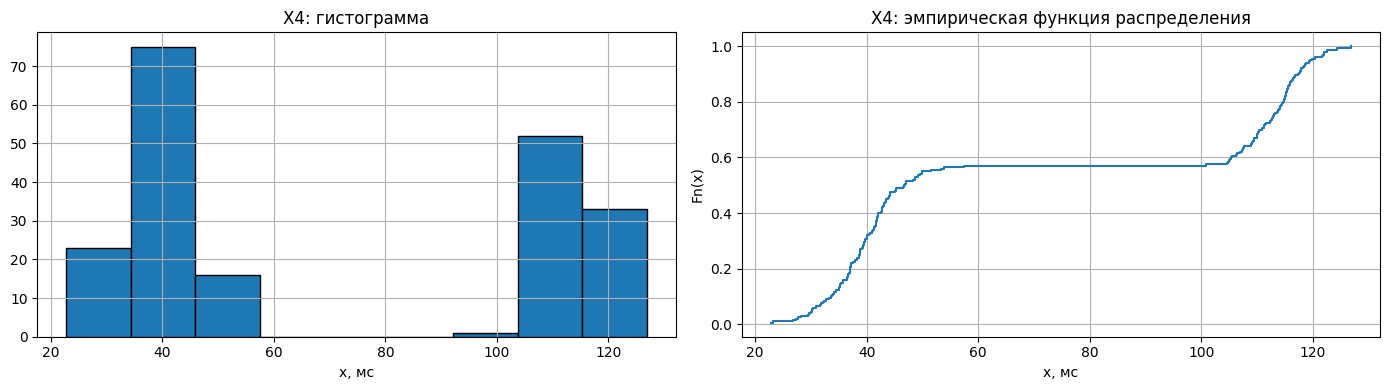

In [21]:

x4 = df["X4"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(x4, bins=sturges_bins(x4), edgecolor="black")
axes[0].set_title("X4: гистограмма")
axes[0].set_xlabel("x, мс")

xs, ys = ecdf(x4)
axes[1].step(xs, ys, where="post")
axes[1].set_title("X4: эмпирическая функция распределения")
axes[1].set_xlabel("x, мс")
axes[1].set_ylabel("Fn(x)")
plt.tight_layout()
plt.show()


In [22]:

kmeans = KMeans(n_clusters=2, random_state=42, n_init=20)
clusters = kmeans.fit_predict(x4.reshape(-1, 1))
centers = kmeans.cluster_centers_.flatten()

x4_clustered = pd.DataFrame({"X4": x4, "cluster": clusters})
cluster_summary = x4_clustered.groupby("cluster")["X4"].agg(["count", "mean", "std", "min", "median", "max"]).round(4)
display(cluster_summary)

plt.figure(figsize=(10, 4))
plt.scatter(np.arange(len(x4)), x4, c=clusters)
plt.xlabel("Номер наблюдения")
plt.ylabel("X4, мс")
plt.title("X4: разбиение на 2 кластера (k-means)")
plt.show()


NameError: name 'KMeans' is not defined

In [ ]:
means = x4_clustered.groupby("cluster")["X4"].mean().sort_values().to_numpy()
display(Markdown(
    f"По столбцу `X4` есть признаки смеси двух групп: после разбиения на 2 кластера "
    f"получаются средние примерно {means[0]:.2f} мс и {means[1]:.2f} мс. "
    "Следовательно, одно общее среднее по всей выборке плохо отражает структуру данных, "
    "потому что лежит между двумя режимами и не является типичным значением ни для одной из групп."
))


По столбцу `X4` есть признаки смеси двух групп: после разбиения на 2 кластера получаются средние примерно 39.30 мс и 113.71 мс. Следовательно, одно общее среднее по всей выборке плохо отражает структуру данных, потому что лежит между двумя режимами и не является типичным значением ни для одной из групп.

## Краткий общий вывод
После всех вычислений остаётся сопоставить полученные числовые результаты с графиками и сделать итоговое заключение по каждому столбцу.
